In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score

# Read the data from a TSV file
# Replace 'your_data.tsv' with the path to your actual data file
df = pd.read_excel('/Users/igor.varha/CCP_workdir/combined_skull_analysis.xlsx')
print(df.columns)
# Display the first few rows to verify data loading
df.describe()

Index(['Unnamed: 0', 'GENDER', 'STRAIN', 'COHORT_ID', 'DATE', 'CraniumLength',
       'SkullShape', 'Comment', 'proc_dist', 'abn_distance', 'area99perc',
       'abn_perc', 's_x', 's_y', 's_z', 'sutures_open'],
      dtype='object')


,DATE,CraniumLength,proc_dist,area99perc,s_x,s_y,s_z,sutures_open
count,6031,5923.000000,5661.000000,5661.000000,5661.000000,5661.000000,5661.000000,1382.000000
mean,2022-10-09 13:49:57.114906368,26.370723,4863.057191,0.089696,1.033463,0.988645,0.947926,0.401592
min,2020-09-28 00:00:00,20.510000,218.461700,0.000000,0.731474,0.445838,0.000046,0.000000
25%,2021-09-06 00:00:00,26.020000,460.465957,0.000865,1.006433,0.979244,0.948132,0.000000
50%,2022-10-31 00:00:00,26.420000,581.166407,0.005726,1.021120,0.992121,0.964642,0.000000
75%,2023-10-23 00:00:00,26.800000,815.342622,0.028708,1.039721,1.004339,0.977676,1.000000
max,2024-10-07 00:00:00,29.040000,737904.180986,1.000000,4.763503,3.013486,1.383324,1.000000
std,NaN,0.733314,32167.039673,0.237535,0.083156,0.052561,0.080690,0.490398


Text(0.5, 1.0, 'Distribution of Abn Perc')

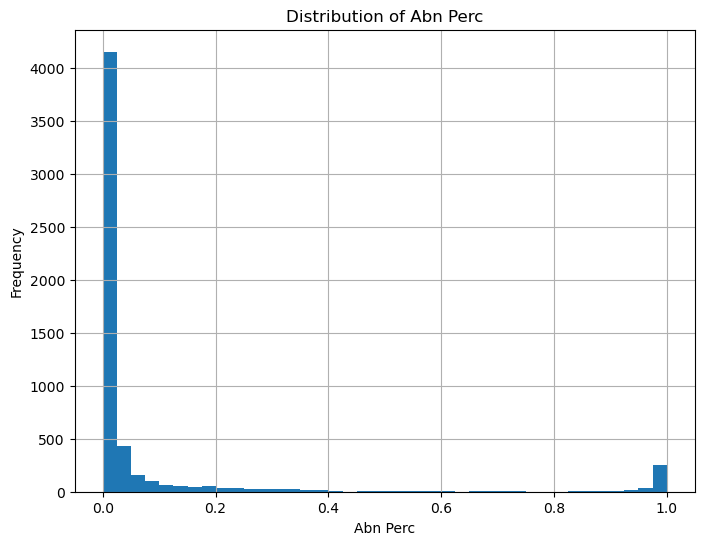

In [2]:
# plot histogram of abn_perc
plt.figure(figsize=(8, 6))
df['area99perc'].hist(bins=40)
plt.xlabel('Abn Perc')
plt.ylabel('Frequency')
plt.title('Distribution of Abn Perc')


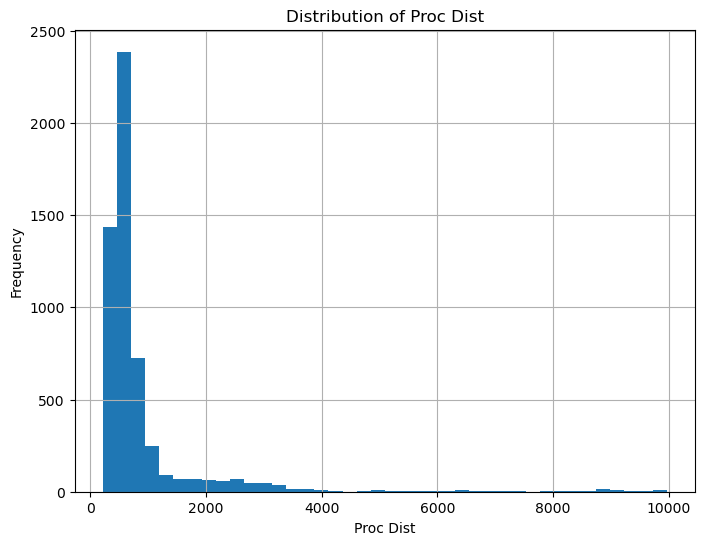

In [3]:
# plot histogram of proc_dist
plt.figure(figsize=(8, 6))
df[df['proc_dist'] < 10000]['proc_dist'].hist(bins=40)
plt.xlabel('Proc Dist')
plt.ylabel('Frequency')
plt.title('Distribution of Proc Dist')
plt.show()

In [4]:
# print amount of subjects where coregistration failed (proc dist > 3000) vs total amount of subjects
print(f"Number of subjects where coregistration failed: {len(df[df['proc_dist'] > 3000])}")
print(f"Total subjects: {len(df)}")
print('Ratio of failed coregistration: ', len(df[df['proc_dist'] > 3000]) / len(df))


Number of subjects where coregistration failed: 385
Total subjects: 6031
Ratio of failed coregistration:  0.06383684297794727


In [5]:
# print first and last cohort

print('First cohort: ', df['COHORT_ID'].min())
print('Last cohort: ', df['COHORT_ID'].max())

# gaps in cohort numbers
cohort_range = range(int(df['COHORT_ID'].min()[1:]), int(df['COHORT_ID'].max()[1:]))
missing_cohorts = set(cohort_range) - set(df['COHORT_ID'].apply(lambda x: int(x[1:])))
print("Missing:" ,{'c' + str(x) for x in missing_cohorts})

First cohort:  c158
Last cohort:  c359
Missing: {'c224', 'c333', 'c222', 'c172', 'c227', 'c218', 'c198', 'c213', 'c183', 'c215', 'c347', 'c266', 'c159', 'c190', 'c212', 'c221', 'c214'}


In [6]:
# Map classification labels to numerical values
label_mapping = {'normal': 0, 'abnormal': 1}

df['manual_label'] = df['SkullShape'].map(label_mapping)
# add auto_label column abn_distance or abn_perc
df['auto_label'] = (df['abn_distance'].map(label_mapping) + df['abn_perc'].map(label_mapping))>0
df['auto_label'] =df['abn_distance'].map(label_mapping)

# Handle any missing or unmapped values
df = df.dropna(subset=['manual_label', 'auto_label'])
print(" ratio of abnormal vs normal: ", df['manual_label'].value_counts())
# drop rows with distance > 1000
df = df[df['proc_dist'] < 2000]
# drop rows where comment contains 'sutures'
df = df[~df['Comment'].str.contains('suture', case=False, na=False)]
print(" ratio of abnormal vs normal: ", df['manual_label'].value_counts())

 ratio of abnormal vs normal:  manual_label
0.0    4206
1.0    1452
Name: count, dtype: int64
 ratio of abnormal vs normal:  manual_label
0.0    3748
1.0      69
Name: count, dtype: int64


In [7]:
# Compute confusion matrix
cm = confusion_matrix(df['manual_label'], df['auto_label'])

# Compute accuracy
accuracy = accuracy_score(df['manual_label'], df['auto_label'])

print("Confusion Matrix:")
print(cm)
print(f"Accuracy: {accuracy * 100:.2f}%")


from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(df['manual_label'], df['auto_label'], target_names=['Normal', 'Abnormal']))

Confusion Matrix:
[[3452  296]
 [  41   28]]
Accuracy: 91.17%
Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.92      0.95      3748
    Abnormal       0.09      0.41      0.14        69

    accuracy                           0.91      3817
   macro avg       0.54      0.66      0.55      3817
weighted avg       0.97      0.91      0.94      3817



In [8]:
# ratio of normal vs abnormal
print('Ratio of normal vs abnormal: ', df['manual_label'].value_counts(normalize=True))

Ratio of normal vs abnormal:  manual_label
0.0    0.981923
1.0    0.018077
Name: proportion, dtype: float64


In [57]:
# Identify disagreements
df['disagreement'] = df['manual_label'] != df['auto_label']

# Number of subjects that need to be recomputed
num_disagreements = df['disagreement'].sum()
total_subjects = len(df)

print(f"Number of disagreements: {num_disagreements}")
print(f"Total subjects: {total_subjects}")
print(f"Subjects needing recomputation: {num_disagreements}")

Number of disagreements: 304
Total subjects: 3114
Subjects needing recomputation: 304


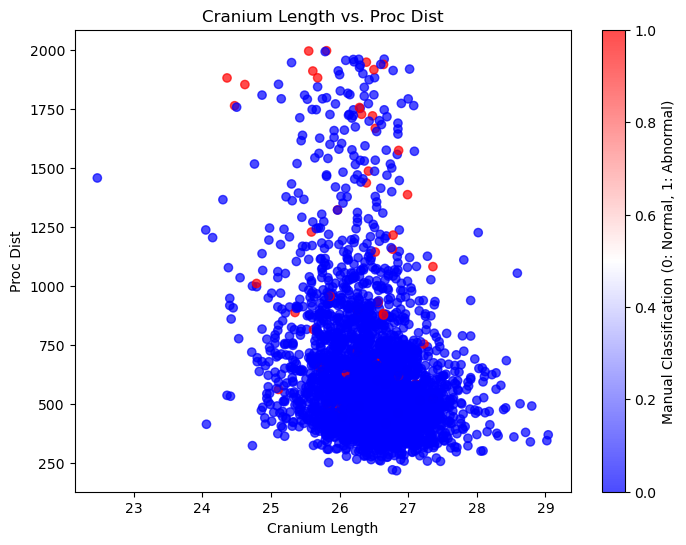

In [32]:
plt.figure(figsize=(8, 6))
plt.scatter(df['CraniumLength'], df['proc_dist'], c=df['manual_label'], cmap='bwr', alpha=0.7)
plt.colorbar(label='Manual Classification (0: Normal, 1: Abnormal)')
plt.xlabel('Cranium Length')
plt.ylabel('Proc Dist')
plt.title('Cranium Length vs. Proc Dist')
plt.show()

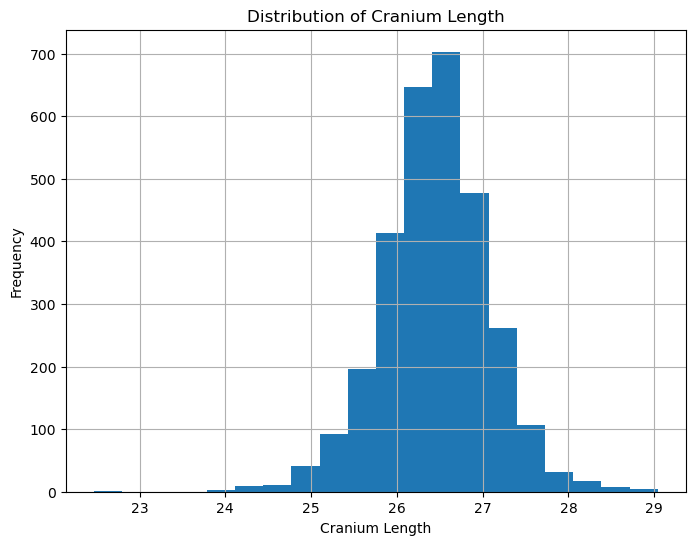

In [33]:
plt.figure(figsize=(8, 6))
df['CraniumLength'].hist(bins=20)
plt.xlabel('Cranium Length')
plt.ylabel('Frequency')
plt.title('Distribution of Cranium Length')
plt.show()

<Figure size 800x600 with 0 Axes>

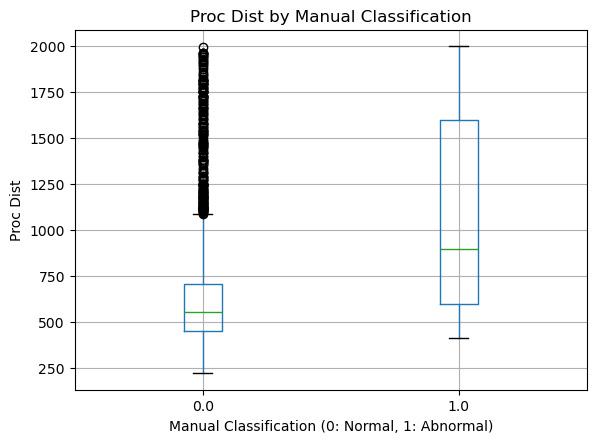

In [34]:
plt.figure(figsize=(8, 6))
df.boxplot(column='proc_dist', by='manual_label')
plt.xlabel('Manual Classification (0: Normal, 1: Abnormal)')
plt.ylabel('Proc Dist')
plt.title('Proc Dist by Manual Classification')
plt.suptitle('')
plt.show()

In [37]:
# Save disagreements to a CSV file
disagreements_df = df[df['disagreement']]
disagreements_df.to_csv('/Users/igor.varha/PycharmProjects/mouseSkullPipelines/test_notebooks/disagreements.csv', index=False)

print("Disagreements have been saved to 'disagreements.csv'.")

Disagreements have been saved to 'disagreements.csv'.


In [67]:
# print accuracy for each cohort
df[df['manual_label']==1]



,Unnamed: 0,GENDER,STRAIN,COHORT_ID,DATE,CraniumLength,SkullShape,Comment,proc_dist,abn_distance,area99perc,abn_perc,s_x,s_y,s_z,manual_label,auto_label,disagreement
118,wt_M_82Z-13354,male,C57Bl/6NCrl,c292,2023-06-12,26.99,abnormal,microphtalmia,644.172500,normal,0.024865,normal,1.014434,1.007554,0.976691,1,0,True
198,Zim1_M_E64-G8150,male,Zim1,c253,2022-08-29,25.35,abnormal,scoliotic; kyphosis high; saddle-like nasalia,888.571772,normal,0.060201,normal,1.001245,0.954327,0.931016,1,0,True
233,Clock_F_E64-G5937,female,Clock,c235,2022-04-19,27.09,abnormal,rostrum malformation,729.510579,normal,0.020407,normal,1.045381,1.010491,0.985403,1,0,True
429,Fam205c_F_E64-F9761,female,Fam205c,c192,2021-05-24,26.55,abnormal,facial assymetry,601.465153,normal,0.000135,normal,1.027898,1.016290,0.981561,1,0,True
521,wt_F_82Z-07486,female,C57Bl/6NCrl,c201,2021-08-09,25.81,abnormal,NaN,1997.261802,abnormal,0.160390,abnormal,1.096868,1.032264,0.952117,1,1,False
672,wt_F_82Z-11047,female,C57Bl/6NCrl,c257,2022-09-27,24.62,abnormal,rostrum malformation,1854.039517,abnormal,0.172995,abnormal,1.008135,0.959628,0.940072,1,1,False
1073,Enpp1_M_E64-CC194,male,Enpp1,c272,2023-01-09,26.39,abnormal,NaN,1948.744049,abnormal,0.301603,abnormal,1.048690,0.974505,0.947891,1,1,False
1074,Enpp1_F_E64-CC161,female,Enpp1,c272,2023-01-09,26.52,abnormal,NaN,1668.277088,abnormal,0.031744,normal,0.998319,0.974962,0.970133,1,1,False
1075,wt_F_82Z-11894,female,C57Bl/6NCrl,c272,2023-01-09,27.11,abnormal,NaN,586.541753,normal,0.000596,normal,1.016167,0.991443,0.952060,1,0,True
1076,Enpp1_M_E64-CC154,male,Enpp1,c272,2023-01-09,26.99,abnormal,NaN,1387.697041,abnormal,0.045771,normal,0.995839,0.978136,0.965084,1,1,False


In [8]:
# get dataframes for just abnormal labelled manually 
abnormal_df = df[df['manual_label']==1]
abnormal_df.to_csv('/Users/igor.varha/PycharmProjects/mouseSkullPipelines/test_notebooks/abnormal_df.csv', index=False)

In [13]:
# searcg Trabd1 gene in the STRAIN column
df[df['Unnamed: 0'].str.contains('tra', case=False, na=False)]

,Unnamed: 0,GENDER,STRAIN,COHORT_ID,DATE,CraniumLength,SkullShape,Comment,proc_dist,abn_distance,area99perc,abn_perc,s_x,s_y,s_z
239,Trak1_F_E64-CE606,female,Trak1 KO,c297,2023-07-17,26.82,normal,T1 not fused,456.955201,normal,0.000749,normal,1.010144,0.999914,0.960015
252,Trak1_M_E64-CE601,male,Trak1 KO,c297,2023-07-17,26.85,normal,NaN,453.410389,normal,0.000058,normal,1.007425,0.964505,0.949837
261,Trak1_F_E64-CE605,female,Trak1 KO,c297,2023-07-17,26.54,abnormal,"T1 not fused, cranial sutures open",374.108515,normal,0.001537,normal,0.994023,0.982701,0.970047
263,Trak1_M_E64-CE600,male,Trak1 KO,c297,2023-07-17,26.95,abnormal,"T1 not fused, L6 = half S0, cranial sutures open",669.671027,normal,0.008109,normal,1.035140,0.988895,0.980681
264,Trak1_M_E64-CE603,male,Trak1 KO,c297,2023-07-17,27.14,normal,NaN,633.340489,normal,0.006725,normal,1.008212,1.000528,0.975955
2228,Trak1_M_E64-CF247,male,Trak1 KO,c305,2023-09-11,26.51,normal,T1 not fused,393.485620,normal,0.003305,normal,1.019377,1.002526,0.976155
3805,Trak1_M_E64-CD748,male,Trak1 KO,c289,2023-05-22,26.99,normal,"pectus excavatum mild, kyphosis",394.730029,normal,0.000769,normal,1.024568,0.994653,0.961920
3821,Trak1_F_E64-CD751,female,Trak1 KO,c289,2023-05-22,26.43,normal,NaN,559.748439,normal,0.002460,normal,1.013058,0.996693,0.982556
4163,Trak1_M_E64-CD743,male,Trak1 KO,c288,2023-05-15,26.48,normal,pectus excavatum severe,685.013392,normal,0.027516,normal,1.059032,1.035445,0.993990
4166,Trak1_F_E64-CD755,female,Trak1 KO,c288,2023-05-15,24.00,abnormal,"T1 not fused, malocclusion, rostrum malformati...",3132.666706,abnormal,0.310288,abnormal,0.992462,0.934755,0.872076


In [14]:
df = df.dropna()

In [15]:
df['man_sutures'] = df['Comment'].str.contains('suture', case=False, na=False)

/var/folders/h4/q7bcqz290p5dmmm6t1r2t72r0000gp/T/ipykernel_50748/2664749283.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['man_sutures'] = df['Comment'].str.contains('suture', case=False, na=False)


In [16]:
# count where sutures are disagreed

df['disagreement'] = df['man_sutures'] != df['sutures_open']

/var/folders/h4/q7bcqz290p5dmmm6t1r2t72r0000gp/T/ipykernel_50748/1188374920.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['disagreement'] = df['man_sutures'] != df['sutures_open']


In [19]:
1- (df['disagreement'].sum()/len(df))

0.7933006535947713

In [18]:
df[df['disagreement']==True]

,Unnamed: 0,GENDER,STRAIN,COHORT_ID,DATE,CraniumLength,SkullShape,Comment,proc_dist,abn_distance,area99perc,abn_perc,s_x,s_y,s_z,sutures_open,man_sutures,disagreement
46,Gtf2ird1_F_E64-CK063,female,Gtf2ird1,c349,2024-07-29,25.76,abnormal,"T1 not fused, kyphosis, pectus excavatum mild,...",886.524471,normal,0.037566,normal,0.983428,0.980646,0.947008,0.0,True,True
49,wt_M_82Z-CJ820,male,C57Bl/6NCrl,c349,2024-07-29,26.55,abnormal,cranial sutures open,237.985792,normal,0.000000,normal,1.054308,1.031607,0.979068,0.0,True,True
51,wt_F_82Z-CJ819,female,C57Bl/6NCrl,c349,2024-07-29,26.46,abnormal,"T1 not fused, cranial sutures open",466.942164,normal,0.000307,normal,0.998293,0.979428,0.968401,0.0,True,True
54,Gfi1b_F_E64-CJ836,female,Gfi1b,c349,2024-07-29,25.60,normal,"T1 not fused, tail cut off (caudal v. 25), kyp...",633.464772,normal,0.000115,normal,0.972523,0.958756,0.930483,1.0,False,True
56,Gtf2ird1_F_E64-CK053,female,Gtf2ird1,c349,2024-07-29,26.84,abnormal,"kyphosis, sternum crooked, cranial sutures open",599.036045,normal,0.003478,normal,1.024102,0.985550,0.960729,0.0,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5997,Gfi1b_M_E64-CJ827,male,Gfi1b,c348,2024-07-22,28.15,abnormal,"T1 not fused, pectus excavatum, cranial suture...",554.320234,normal,0.001614,normal,1.028016,1.014850,0.992579,0.0,True,True
6000,wt_F_82Z-CJ812,female,C57Bl/6NCrl,c348,2024-07-22,25.41,abnormal,"pectus excavatum, kyphosis, cranial sutures op...",1616.248595,abnormal,0.129857,abnormal,0.987355,0.960417,0.932900,0.0,True,True
6001,wt_F_82Z-CJ810,female,C57Bl/6NCrl,c348,2024-07-22,26.44,abnormal,cranial sutures open,699.477060,normal,0.005784,normal,1.040490,0.974860,0.961428,0.0,True,True
6002,wt_F_82Z-CJ811,female,C57Bl/6NCrl,c348,2024-07-22,25.74,abnormal,"T1 not fused, cranial sutures open",358.079957,normal,0.000826,normal,1.018115,0.977308,0.961800,0.0,True,True


<Axes: >

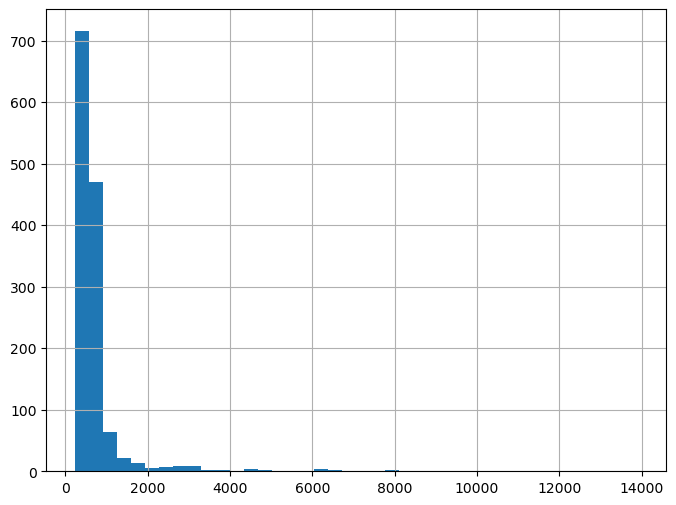

In [23]:
# plot histogram of proc_dist after cohort 315

plt.figure(figsize=(8, 6))
df[df['COHORT_ID']>'c316']['proc_dist'].hist(bins=40)

In [26]:
df[df['COHORT_ID']>'c316'].sort_values(by='proc_dist', ascending=False)

,Unnamed: 0,GENDER,STRAIN,COHORT_ID,DATE,CraniumLength,SkullShape,Comment,proc_dist,abn_distance,area99perc,abn_perc,s_x,s_y,s_z,sutures_open
806,Wdr63_M_E64-CK990,male,Wdr63,c359,2024-10-07,27.50,abnormal,"T1 not fused, hydrocephalus, cranial sutures o...",13912.873370,abnormal,0.823450,abnormal,0.984767,0.928388,0.841989,0.0
5013,Fgf23HOM_F_E64-CK321,female,Fgf23,c351,2024-08-12,21.14,abnormal,"hyperossification (ribs, vertebrae fusion..), ...",11755.493265,abnormal,0.952173,abnormal,1.245237,0.934361,0.910054,1.0
929,Ltbp3_F_E64-CI234,female,Ltbp3,c335,2024-04-08,22.83,abnormal,"scoliotic, C6 + C7 fused, maxilla shorter + de...",7897.095606,abnormal,0.716806,abnormal,1.039873,0.966835,0.881074,1.0
2316,Zfp518b_F_E64-CK522,female,Zfp518b,c354,2024-09-02,22.46,abnormal,"C5 arch fused to C4, L6 processes bone density...",7884.838087,abnormal,0.485012,abnormal,1.014432,0.950868,0.887448,1.0
5990,JkampR182STOP_F_E64-CJ905,female,Jkamp R182STOP,c348,2024-07-22,22.96,abnormal,"tail tip deformed, 24 caudal v., pectus excava...",7063.252076,abnormal,0.609469,abnormal,1.009175,0.906080,0.854858,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3216,wt_M_82Z-CI654,male,C57Bl/6NCrl,c317,2023-12-04,26.86,normal,NaN,272.782023,normal,0.000000,normal,1.066215,1.033195,0.997184,0.0
5702,wt_F_82Z-15172,female,C57Bl/6NCrl,c318,2023-12-11,26.66,abnormal,"scoliotic mild, Ca 26 + 27 fused, kyphosis, cr...",255.088220,normal,0.000000,normal,1.028147,0.986411,0.982034,1.0
49,wt_M_82Z-CJ820,male,C57Bl/6NCrl,c349,2024-07-29,26.55,abnormal,cranial sutures open,237.985792,normal,0.000000,normal,1.054308,1.031607,0.979068,0.0
3713,Gm5148_M_E64-CG586,male,Gm5148,c322,2024-01-08,26.71,normal,kyphosis,222.442894,normal,0.000000,normal,1.012438,0.997085,0.973444,0.0


In [ ]:
# sort by proc_dist 
